# 9.2 Воронки и конверсии — код страницы

Аналитика 101 · блок «Дата аналитика» · тема 09 «Продуктовые метрики и события» · страница 9.2.

В ноутбуке два блока кода страницы на pandas: воронка по сегментам, где виден парадокс Симпсона, и график воронки столбцами. Первый блок страницы — воронка на SQL с окном и строгим порядком — лежит рядом файлом `funnel.sql`, ему нужен PostgreSQL. Данные учебные: журнал событий и аккаунты из общего набора темы `data/events/`.

**Как работать.** Выполняйте ячейки по порядку сверху вниз: график продолжает блок сегментов.

Вывод получен на Python 3.13, pandas 3.0, pyarrow 26 и matplotlib 3.10.

## Где лежат данные

Код страницы читает файлы по пути от корня папки с материалами: `data/events/events.parquet` и `data/events/users.csv`. Ноутбук лежит в папке страницы, поэтому первая ячейка поднимается до папки, в которой есть `data/`, и делает её рабочей. Туда же второй блок сохранит рисунок `funnel_bars.svg`.

In [1]:
import os
import pathlib
import platform

import matplotlib
import pandas as pd
import pyarrow

root = pathlib.Path.cwd()
while not (root / "data" / "events").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/events/
assert (root / "data" / "events" / "events.parquet").exists(), \
    "Не найдена папка data/events/. Скачайте общий набор темы 09 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| pyarrow", pyarrow.__version__,
      "| matplotlib", matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | pyarrow 26.0.1 | matplotlib 3.10.0


## Код: сегменты и график

### Та же воронка по сегментам в pandas: в каждом канале приложение лучше, в сумме — хуже

In [2]:
import pandas as pd

MSK = "Europe/Minsk"
ev = pd.read_parquet("data/events/events.parquet")
users = pd.read_csv("data/events/users.csv", parse_dates=["signup_time"])

# соглашения темы: без дублей, без ботов, человек = аккаунт, время по Минску
ev = ev.drop_duplicates("event_id")
ev["t"] = ev.event_time.dt.tz_convert(MSK)
cl = ev[ev.origin == "client"]
per_day = cl.groupby(["anonymous_id", cl.t.dt.date]).size()
bots = per_day[per_day > 100].index.get_level_values(0).unique()
ev = ev[~ev.anonymous_id.isin(bots)]
dev = ev.dropna(subset=["anonymous_id", "user_id"]).groupby("anonymous_id").user_id.first()
ev["person"] = ev.user_id.fillna(ev.anonymous_id.map(dev)).fillna(ev.anonymous_id)

STEPS = ["app_open", "product_view", "add_to_cart", "checkout_start", "order_paid"]

def funnel(ev, start, window="7D"):
    """Любой порядок: человек дошёл до шага k, если в окне есть все шаги 1…k."""
    e = ev[ev.event_name.isin(STEPS)].merge(start.rename("t0"), left_on="person", right_index=True)
    e = e[(e.t >= e.t0) & (e.t <= e.t0 + pd.Timedelta(window))]
    has = (e.pivot_table(index="person", columns="event_name", values="t", aggfunc="size")
             .reindex(index=start.index, columns=STEPS).notna())
    return has.cummin(axis=1)                 # шаг засчитан, только если засчитаны все до него

first = ev[ev.event_name == "app_open"].sort_values("t").groupby("person").first()
old = users.loc[users.signup_time < pd.Timestamp("2026-01-05", tz=MSK), "user_id"]
new = first[~first.index.isin(old) & (first.t < pd.Timestamp("2026-06-22", tz=MSK))]
reach = funnel(ev, new.t)                     # окно 7 суток успело закрыться у всех

seg = pd.DataFrame({
    "канал": new.traffic_source.replace({"search": "органика", "direct": "органика", "partner": "партнёры",
                                         "ad": "реклама", "push": "прочее", "email": "прочее"}),
    "платформа": new.platform.replace({"android": "приложение", "ios": "приложение", "web": "сайт"}),
    "оплатил": reach["order_paid"]})
kw = dict(index="канал", columns="платформа", values="оплатил", margins=True, margins_name="всего")
rate = seg.pivot_table(aggfunc="mean", **kw) * 100   # доля оплативших → проценты
size = seg.pivot_table(aggfunc="count", **kw)        # сколько людей в ячейке
order = ["органика", "партнёры", "реклама", "прочее", "всего"]
print(rate.reindex(order).round(1), size.reindex(order), sep="\n\n")

платформа  приложение  сайт  всего
канал                             
органика         23.8  16.7   21.5
партнёры         39.7  36.8   37.3
реклама          12.2  10.4   11.8
прочее            4.0   3.3    3.5
всего            19.4  23.7   21.1

платформа  приложение  сайт  всего
канал                             
органика         2624  1260   3884
партнёры          272  1374   1646
реклама          2257   557   2814
прочее             50    92    142
всего            5203  3283   8486


Журнал и аккаунты — общий набор data/events/. margins=True добавляет строку и столбец «всего»: в нём и прячется парадокс.

### График воронки без «воронки»: столбцы, доля перехода и один акцент

{'app_open': 1610, 'product_view': 1525, 'add_to_cart': 654, 'checkout_start': 344, 'order_paid': 329}
переходы, %: {'product_view': 94.7, 'add_to_cart': 42.9, 'checkout_start': 52.6, 'order_paid': 95.6}


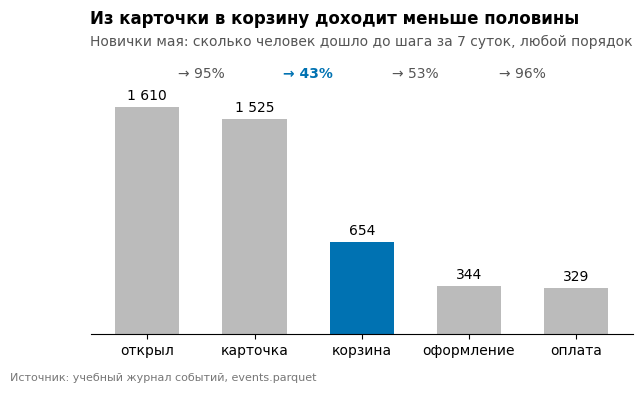

In [3]:
import matplotlib.pyplot as plt

plt.rcParams["svg.fonttype"] = "none"         # подписи в SVG остаются текстом

may = first[~first.index.isin(old)
            & (first.t >= pd.Timestamp("2026-05-01", tz=MSK))
            & (first.t < pd.Timestamp("2026-06-01", tz=MSK))]
n = funnel(ev, may.t).sum()                   # дошли до шага: окно 7 суток, любой порядок
step = n / n.shift()                          # доля перехода с прошлого шага
worst = step.idxmin()                         # где теряем больше всего
print(n.to_dict())
print("переходы, %:", (step.iloc[1:] * 100).round(1).to_dict())
assert worst == "add_to_cart" and step[worst] < 0.5, "заголовок данными не подтверждается"

GREY, ACCENT = "#BBBBBB", "#0072B2"
names = ["открыл", "карточка", "корзина", "оформление", "оплата"]
colors = [ACCENT if s == worst else GREY for s in STEPS]
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(names, n, color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{v:,}".replace(",", " ") for v in n], padding=3, fontsize=10)
for i in range(1, 5):                         # доля перехода — над промежутком между столбцами
    on = STEPS[i] == worst
    ax.text(i - 0.5, n.max() * 1.13, f"→ {step.iloc[i]:.0%}", ha="center",
            fontsize=10, color=ACCENT if on else "#555555", fontweight="bold" if on else "normal")
ax.set_ylim(0, n.max() * 1.22)
ax.set_yticks([])                              # подписи на столбцах заменяют ось
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_title("Из карточки в корзину доходит меньше половины", loc="left", fontweight="bold", pad=24)
ax.text(0, 1.04, "Новички мая: сколько человек дошло до шага за 7 суток, любой порядок",
        transform=ax.transAxes, color="#555555")
fig.text(0.01, -0.02, "Источник: учебный журнал событий, events.parquet", fontsize=8, color="#777777")
fig.savefig("funnel_bars.svg", bbox_inches="tight")

Продолжение блока выше: ev, first, old, funnel, STEPS и MSK — оттуда. Рисунок ниже — настоящий вывод этого кода, SVG с текстом вместо кривых.